# **Copyright and Author Information**

Copyright © [2024] Docketrun Tech Private Limited. All rights reserved.

This notebook is open-sourced and available under the [MIT License](https://opensource.org/licenses/MIT).

Author: Yahiya Mulla

This Colab notebook is provided for educational and informational purposes only. You are free to use, modify, and distribute it, provided that proper attribution is given.

**Disclaimer:** The information in this notebook is provided "as is," without warranty of any kind. The authors or the company do not accept any responsibility for errors or omissions in the content.

# **Image processing**

---

## **Import Libraries**
*   **from google.colab import files**: This imports the files module from the Google
Colab library, which allows you to upload files (e.g., images) from your local machine to the Colab environment.
*   **import cv2**: This imports the OpenCV library, which is used for image processing tasks such as reading, writing, and manipulating images.
*   **from matplotlib import pyplot as plt**: This imports the pyplot module from the matplotlib library, which is used for displaying images and creating plots.

In [1]:
from google.colab import files
import cv2
from matplotlib import pyplot as plt

## **Upload the Image**
**uploaded = files.upload()**:

This line of code opens a file dialog in the Colab notebook, allowing you to select and upload an image from your local machine. The variable **uploaded** is a dictionary where the keys are the filenames of the uploaded files, and the values are the file data (in bytes). After uploading, you can access the image using the filename.

In [6]:
# Upload the image
uploaded = files.upload()

Saving image.jpeg to image.jpeg


## **Reading the image**
**cv2.imread()** reads an image from the file system and loads it into a variable. '**image.jpeg**' is the file path of the image you want to load.

This function reads the image and returns it as a NumPy array. The image is loaded in **BGR** (Blue, Green, Red) format by default, which is the standard color format used by OpenCV.

In [7]:
image = cv2.imread('image.jpeg')

## **Converting Color Spaces**

**cv2.cvtColor(image, cv2.COLOR_BGR2RGB)**:

*   **image**: The image loaded in BGR format.
*   **cv2.COLOR_BGR2RGB**: This is a flag that specifies the conversion from BGR to RGB color space. cv2.COLOR_BGR2RGB indicates that OpenCV should convert the image from BGR (used by OpenCV) to RGB (used by Matplotlib).
*   **cv2.cvtColor()**: This function performs the color space conversion and returns the image in RGB format.

**plt.imshow(image_rgb)**:

This function displays the image using Matplotlib. **image_rgb** is the image in RGB format, which is compatible with Matplotlib’s imshow() function.

**plt.axis('off')**:

This function turns off the axis labels and ticks on the plot. It makes the display cleaner by hiding the axes around the image.

**plt.show()**:

This function renders the plot and displays it in the output cell. It is necessary to call this function to actually visualize the image in Colab notebooks.

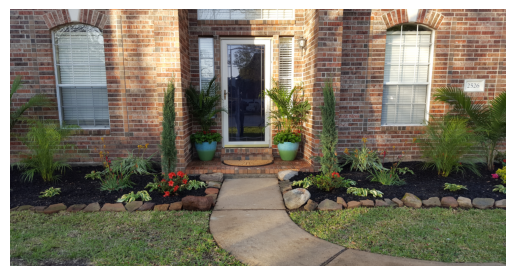

In [8]:
# Convert BGR to RGB for displaying with matplotlib
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display the image
plt.imshow(image_rgb)
plt.axis('off')
plt.show()

Now lets try converting the image into **grayscale**

**cv2.COLOR_BGR2GRAY** is the color conversion code used to specify that the image should be converted from **BGR** (Blue, Green, Red) to **GRAY** (grayscale).

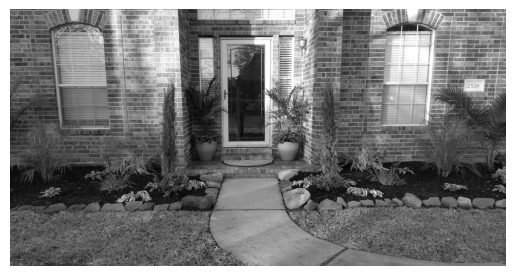

In [9]:
# Convert the image to grayscale
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Display the grayscale image
plt.imshow(gray_image, cmap='gray')
plt.axis('off')
plt.show()

## **Resizing an Image**

**image.shape** returns a tuple representing the dimensions of the image.

In [10]:
# printing the shape of the image
print( image.shape )

(2752, 5312, 3)


**cv2.resize()** function is used to change the size of an image to the specified width and height.

**image** is the input image that you want to resize and **(500, 500)** tuple specifies the new size of the image i.e 500 width and 500 height.

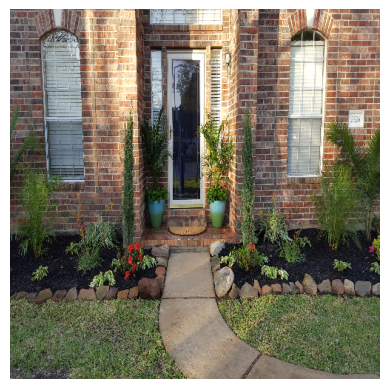

(500, 500, 3)


In [11]:
# Resizing the image to 500 x 500
resized_image = cv2.resize(image, (500, 500))

# Convert BGR to RGB for displaying with matplotlib
resized_image_rgb = cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB)

# Display the resized image
plt.imshow(resized_image_rgb)
plt.axis('off')
plt.show()

# printing the shape of the image
print( resized_image.shape )

## **Image Blurring**

**cv2.GaussianBlur()** function applies a **Gaussian blur** to an image. Gaussian blur is a common image processing technique used to **reduce noise** **and** **detail** in an image. It works by averaging the pixels within a kernel to smooth out rapid changes in intensity.

**image** is the input image to which the Gaussian blur will be applied and **(15, 15)** tuple specifies the size of the Gaussian kernel. In this case, the kernel is 15 pixels wide and 15 pixels high.

**NOTE: The kernel size must be positive and odd. Larger kernel sizes result in more blurring.**

**0** parameter specifies the standard deviation in the X direction (**sigmaX**) for the Gaussian kernel. **sigmaX** Controls the extent of the blur in the X direction. The default value of 0 means that the function will calculate an appropriate value based on the kernel size.

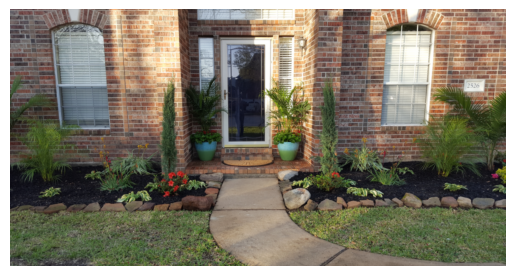

In [12]:
# Apply Gaussian Blur
blurred_image = cv2.GaussianBlur(image, (15, 15), 0)

# Convert BGR to RGB for displaying with matplotlib
blurred_image_rgb = cv2.cvtColor(blurred_image, cv2.COLOR_BGR2RGB)

# Display the blurred image
plt.imshow(blurred_image_rgb)
plt.axis('off')
plt.show()


## **Edge Detection**

**cv2.Canny()** function is used to **detect edges** in an image using the **Canny edge detection algorithm**. This algorithm is a popular method for edge detection due to its accuracy and efficiency.

**gray_image** is the input image on which edge detection is performed. Edge detection generally works on grayscale images as color information is not required for finding edges.

**100** parameter is the first threshold for the edge detection algorithm. It is used to determine whether a gradient magnitude is strong enough to be considered an edge. Values below this threshold are discarded.

**120** parameter is the second threshold for the edge detection algorithm. It is used to identify strong edges. Pixels with gradient magnitudes above this threshold are considered strong edges, while those between the two thresholds are considered weak edges.


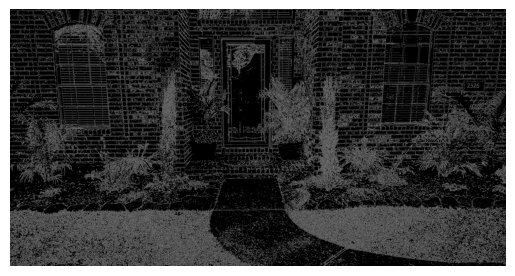

In [13]:
# we will use canny edge detector to detect the edges.
edges = cv2.Canny(gray_image, 100, 120)

# Display the edges
plt.imshow(edges, cmap='gray')
plt.axis('off')
plt.show()

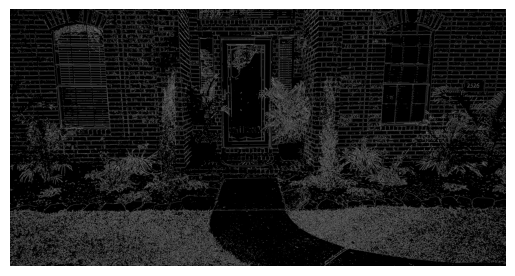

In [29]:
# Experiment with GaussianBlur and Canny
blurred_gray = cv2.GaussianBlur(gray_image, (5,5), 0)
edges = cv2.Canny(blurred_gray, 100, 120)

# Display the edges
plt.imshow(edges, cmap= 'gray')
plt.axis('off')
plt.show()

In my experiment, applied to my house photo, I changed the kernal to (5,5) vs the preset (15, 15) Gaussian kernel, many of the tiny brick and plant details disappeared, leaving the larger structural edges more prominent. The (5, 5) still suppresses some tiny noise, but a lot more meaningful detail is preserved than with (15,15). You can clearly see the brick pattern, window frames, door, plants, and walkway edges again that were not as visible with a larger kernal, which allows Canny detection.
A real-world use is noise reduction before edge detection or object recognition. For example, a security camera image may have sensor noise, tiny texture details, or compression artifacts. A Gaussian blur smooths those small fluctuations so the next step—like Canny edge detection—doesn’t mistake every tiny speck or brick texture for a meaningful edge. Another common use is in photo editing and smartphone cameras, where this technique can soften backgrounds, reduce visible noise, or help create effects like depth-of-field.



## **Thresholding**

**cv2.threshold()** function is used to apply a **thresholding operation** to an image. Thresholding converts a **grayscale image** to a **binary image (black and white)** based on a specified threshold value.

**gray_image** is the input grayscale image to which the thresholding operation will be applied.

**100** is the threshold value used to classify pixel values into two categories. Pixels with intensity values **greater than or equal** to this threshold will be set to the **maximum value (255)**, while pixels with intensity values **less than** this threshold will be set to **0**.

**255** is the maximum intensity value to be assigned to pixels that meet the threshold condition.

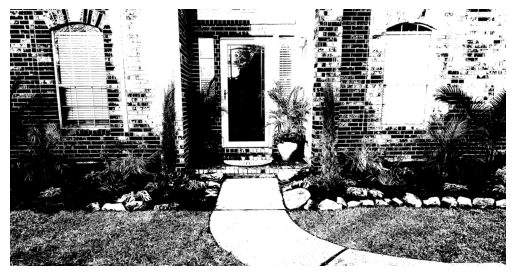

In [14]:
# Apply binary thresholding
_, binary_image = cv2.threshold(gray_image, 100, 255, cv2.THRESH_BINARY)

# Display the binary image
plt.imshow(binary_image, cmap='gray')
plt.axis('off')
plt.show()

## **Image Cropping**

**image** is the input image from which you want to crop a specific region. It is represented as a **NumPy array** in OpenCV, where the array dimensions correspond to the height, width, and color channels of the image.

General syntax is **image[y1:y2, x1:x2]** where **25:174** represents **y1:y2** and **80:185** represents **x1:x2**.

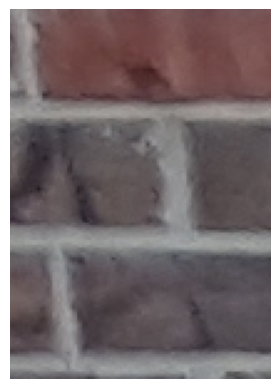

In [15]:
# Crop the image (y1:y2, x1:x2)
cropped_image = image[25:174, 80:185]

# Convert BGR to RGB for displaying with matplotlib
cropped_image_rgb = cv2.cvtColor(cropped_image, cv2.COLOR_BGR2RGB)

# Display the cropped image
plt.imshow(cropped_image_rgb)
plt.axis('off')
plt.show()

## **Drawing on Images**

**image_copy = image.copy()**: copy() method is used to create a deep copy of a NumPy array. In the context of image processing with OpenCV, it creates a new image that is a duplicate of the original image.

**cv2.rectangle()** function is used to draw a rectangle on an image. **image_copy** is the image on which the rectangle will be drawn, **(50, 50)** tuple represents the coordinates of the top-left corner of the rectangle, **(185, 174)** tuple represents the coordinates of the bottom-right corner of the rectangle, **(0, 255, 0)** tuple represents the color of the rectangle in BGR (Blue, Green, Red) format and **3** parameter specifies the thickness of the rectangle’s border in pixels.

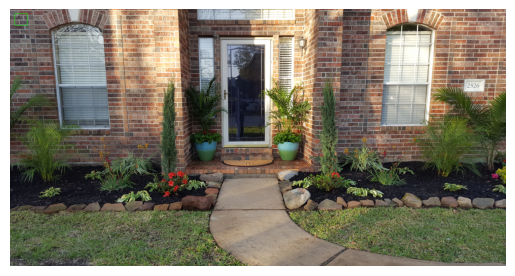

In [16]:
# creating copy of the image
image_copy = image.copy()

# Draw a rectangle on the image
cv2.rectangle(image_copy, (50, 50), (185, 174), (0, 255, 0), 3)

# Convert BGR to RGB for displaying with matplotlib
image_rgb_with_shapes = cv2.cvtColor(image_copy, cv2.COLOR_BGR2RGB)

# Display the image with drawings
plt.imshow(image_rgb_with_shapes)
plt.axis('off')
plt.show()

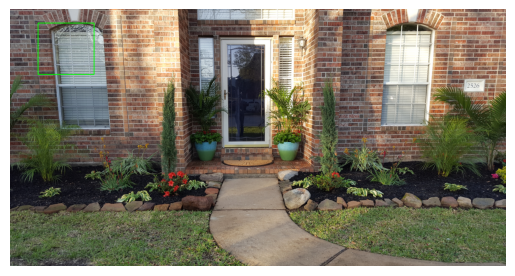

In [31]:
# Experiment create a larger rectangle
image_copy = image.copy()

# Draw a rectangle on the image
cv2.rectangle(image_copy, (300, 150), (900, 700), (0, 255, 0), 8)

# Convert BGR to RGB for displaying with matplotlib
image_rgb_with_shapes = cv2.cvtColor(image_copy, cv2.COLOR_BGR2RGB)

# Display the image with drawings
plt.imshow(image_rgb_with_shapes)
plt.axis('off')
plt.show()

**cv2.circle()** function is used to draw a circle on an image. **image_copy** is the image on which the circle will be drawn, **(100, 100)** tuple represents the coordinates of the center of the circle, **100** parameter specifies the radius of the circle in pixels, **(255, 0, 0)** tuple represents the color of the circle in BGR (Blue, Green, Red) format and **-1** parameter specifies the thickness of the circle’s border. A value of -1 means the circle will be filled with the specified color. If a positive value is used, it specifies the thickness of the circle’s border, and the circle will not be filled.

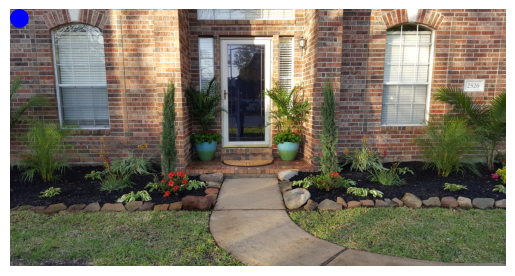

In [17]:
# creating copy of the image
image_copy = image.copy()

# Draw a circle on the image
cv2.circle(image_copy, (100, 100), 100, (255, 0, 0), -1)

# Convert BGR to RGB for displaying with matplotlib
image_rgb_with_shapes = cv2.cvtColor(image_copy, cv2.COLOR_BGR2RGB)

# Display the image with drawings
plt.imshow(image_rgb_with_shapes)
plt.axis('off')
plt.show()

## **Flipping an image**

**cv2.flip()** function is used to flip or mirror an image along a specified axis. This function allows you to perform horizontal and vertical flips. **image** is the input image to be flipped and **1** parameter specifies the axis along which to flip the image. Here **0** represents Flip vertically (around the x-axis), **1** represents Flip horizontally (around the y-axis) and **-1** represents Flip both vertically and horizontally.

**plt.figure(figsize=(10, 5))** creates a new figure (or window) for plotting. The figsize parameter specifies the dimensions of the figure in inches.

**plt.subplot(1, 3, 1)** function defines a subplot within the figure. It allows you to arrange multiple plots in a grid layout. The first parameter (1) specifies the number of rows in the grid, The second parameter (3) specifies the number of columns in the grid and The third parameter (1) specifies the index of the current subplot in the grid layout (in this case, the first subplot).

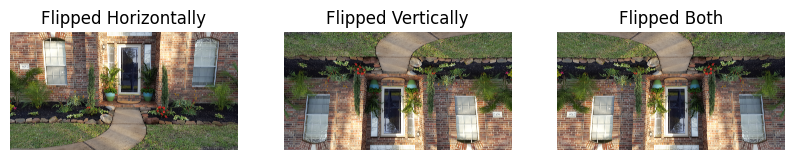

In [18]:
# Flip horizontally
flipped_horizontally = cv2.flip(image, 1)

# Flip vertically
flipped_vertically = cv2.flip(image, 0)

# Flip both horizontally and vertically
flipped_both = cv2.flip(image, -1)

# Step 3: Convert BGR to RGB for displaying with matplotlib
flipped_horizontally_rgb = cv2.cvtColor(flipped_horizontally, cv2.COLOR_BGR2RGB)
flipped_vertically_rgb = cv2.cvtColor(flipped_vertically, cv2.COLOR_BGR2RGB)
flipped_both_rgb = cv2.cvtColor(flipped_both, cv2.COLOR_BGR2RGB)

# Display the original and flipped images
plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.imshow(flipped_horizontally_rgb)
plt.axis('off')
plt.title('Flipped Horizontally')

plt.subplot(1, 3, 2)
plt.imshow(flipped_vertically_rgb)
plt.axis('off')
plt.title('Flipped Vertically')

plt.subplot(1, 3, 3)
plt.imshow(flipped_both_rgb)
plt.axis('off')
plt.title('Flipped Both')

plt.show()

## **Adding two images**

**cv2.add()** function performs **pixel-wise addition** of two images. This means that the function adds the corresponding pixel values from **image1** and **image2** to produce a new image **added_image**. It also supports adding a **scalar value** to an image. This operation adds the scalar value to each channel (BGR) of every pixel in the image.

image1 shape: (2752, 5312, 3), image2 shape: (2752, 5312, 3)


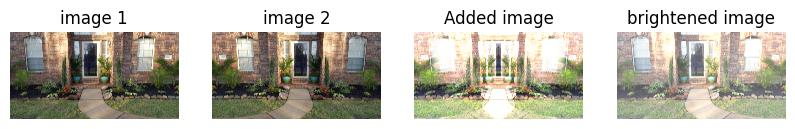

In [19]:
image1 = image.copy()
image2 = flipped_horizontally.copy()

print( "image1 shape: {0}, image2 shape: {1}".format( image1.shape, image2.shape ) )

# Add the images
added_image = cv2.add(image1, image2)

# Add a scalar value to each pixel in the image (increase brightness)
brightened_image = cv2.add(image1, 80)

image1 = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
image2 = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)
added_image = cv2.cvtColor(added_image, cv2.COLOR_BGR2RGB)
brightened_image = cv2.cvtColor(brightened_image, cv2.COLOR_BGR2RGB)

# Display the original and flipped images
plt.figure(figsize=(10, 5))

plt.subplot(1, 4, 1)
plt.imshow(image1)
plt.axis('off')
plt.title('image 1')

plt.subplot(1, 4, 2)
plt.imshow(image2)
plt.axis('off')
plt.title('image 2')

plt.subplot(1, 4, 3)
plt.imshow(added_image)
plt.axis('off')
plt.title('Added image')

plt.subplot(1, 4, 4)
plt.imshow(brightened_image)
plt.axis('off')
plt.title('brightened image')

plt.show()

## **Subtracting two images**

**cv2.subtract()** function performs **pixel-wise subtraction** of two images. This means that for each corresponding pixel in the two images, the function subtracts the pixel value in **image2** from the pixel value in **image1**. It also supports subtracting a scalar value to an image. This operation removes the scalar value to each channel (BGR) of every pixel in the image.

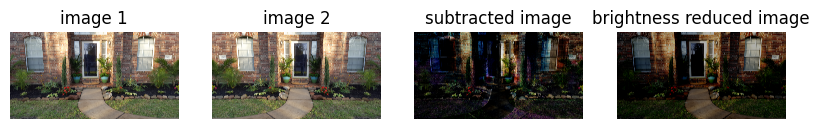

In [20]:
image1 = image.copy()
image2 = flipped_horizontally.copy()

# Subtract the second image from the first
subtracted_image = cv2.subtract(image1, image2)

# Subtract the second image from the first
reduced_brightness = cv2.subtract(image1, 80)

image1 = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
image2 = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)
subtracted_image = cv2.cvtColor(subtracted_image, cv2.COLOR_BGR2RGB)
reduced_brightness = cv2.cvtColor(reduced_brightness, cv2.COLOR_BGR2RGB)

# Display the original and flipped images
plt.figure(figsize=(10, 5))

plt.subplot(1, 4, 1)
plt.imshow(image1)
plt.axis('off')
plt.title('image 1')

plt.subplot(1, 4, 2)
plt.imshow(image2)
plt.axis('off')
plt.title('image 2')

plt.subplot(1, 4, 3)
plt.imshow(subtracted_image)
plt.axis('off')
plt.title('subtracted image')

plt.subplot(1, 4, 4)
plt.imshow(reduced_brightness)
plt.axis('off')
plt.title('brightness reduced image')

plt.show()

## **Multiplication of two images**

**cv2.multiply()** function performs element-wise (pixel-by-pixel) multiplication of two images. Each pixel value in the output image is the product of the corresponding pixel values from **image1** and **image2**. It also supports multiplying an image by a scalar value. When you multiply an image by a scalar, every pixel in the image is multiplied by that scalar value.

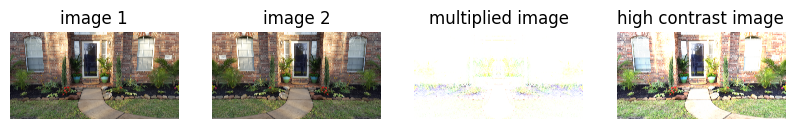

In [21]:
image1 = image.copy()
image2 = flipped_horizontally.copy()

# Multiply the two images
multiplied_image = cv2.multiply(image1, image2)

# Multiply the image by a scalar value (increase contrast)
high_contrast_image = cv2.multiply(image1, 2.0)

image1 = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
image2 = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)
multiplied_image = cv2.cvtColor(multiplied_image, cv2.COLOR_BGR2RGB)
high_contrast_image = cv2.cvtColor(high_contrast_image, cv2.COLOR_BGR2RGB)

# Display the original and flipped images
plt.figure(figsize=(10, 5))

plt.subplot(1, 4, 1)
plt.imshow(image1)
plt.axis('off')
plt.title('image 1')

plt.subplot(1, 4, 2)
plt.imshow(image2)
plt.axis('off')
plt.title('image 2')

plt.subplot(1, 4, 3)
plt.imshow(multiplied_image)
plt.axis('off')
plt.title('multiplied image')

plt.subplot(1, 4, 4)
plt.imshow(high_contrast_image)
plt.axis('off')
plt.title('high contrast image')

plt.show()

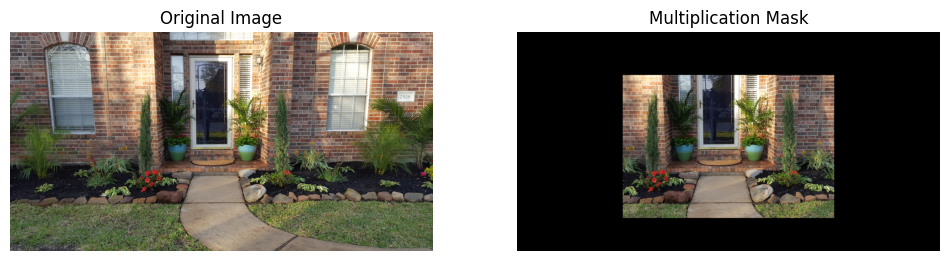

In [32]:
import numpy as np

# Experiment: Use multiplication to isolate a region of interest

# Create a mask the same size as the image
mask = np.zeros_like(image)

# Get image dimensions
height, width = image.shape[:2]

# Keep the center portion of the image
y1, y2 = int(height * 0.20), int(height * 0.85)
x1, x2 = int(width * 0.25), int(width * 0.75)

# Set the ROI to 1; everything else remains 0
mask[y1:y2, x1:x2] = 1

# Multiply image by mask
masked_image = cv2.multiply(image, mask)

# Convert to RGB for Matplotlib
original_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
masked_rgb = cv2.cvtColor(masked_image, cv2.COLOR_BGR2RGB)

# Display comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(masked_rgb)
plt.title("Multiplication Mask")
plt.axis("off")

plt.show()

Multiplying the image by a binary mask demonstrated how multiplication can isolate a region of interest. Pixels multiplied by 1 remained visible, while pixels multiplied by 0 became black.
Real-world examples would be MRI imaging with a tumor mask, the “region of interest” (ROI).  Anything multiplied by 0 disappears and the tumor area, multiplied by 1 stays. This is also applied in satellite imagery, multipying an aerial image by a land-use mask to keep only roads, water, or buildings.


## **Division of two images**

**cv2.divide()** function performs pixel-by-pixel **division** of two images. This means that for each corresponding pixel in the two images, the function divides the pixel value in **image1** by the pixel value in **image2**. It also support scalar division, where a single scalar value is used to divide each pixel in an image.

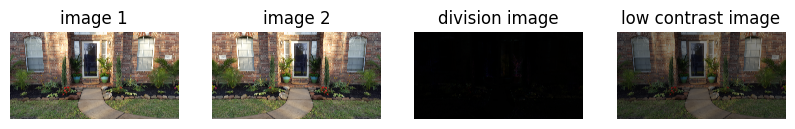

In [22]:
image1 = image.copy()
image2 = flipped_horizontally.copy()

# Divide the first image by the second image
divided_image = cv2.divide(image1, image2)

# Divide the image by a scalar value (reduce contrast)
low_contrast_image = cv2.divide(image1, 2.0)

image1 = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
image2 = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)
divided_image = cv2.cvtColor(divided_image, cv2.COLOR_BGR2RGB)
low_contrast_image = cv2.cvtColor(low_contrast_image, cv2.COLOR_BGR2RGB)

# Display the original and flipped images
plt.figure(figsize=(10, 5))

plt.subplot(1, 4, 1)
plt.imshow(image1)
plt.axis('off')
plt.title('image 1')

plt.subplot(1, 4, 2)
plt.imshow(image2)
plt.axis('off')
plt.title('image 2')

plt.subplot(1, 4, 3)
plt.imshow(divided_image)
plt.axis('off')
plt.title('division image')

plt.subplot(1, 4, 4)
plt.imshow(low_contrast_image)
plt.axis('off')
plt.title('low contrast image')

plt.show()

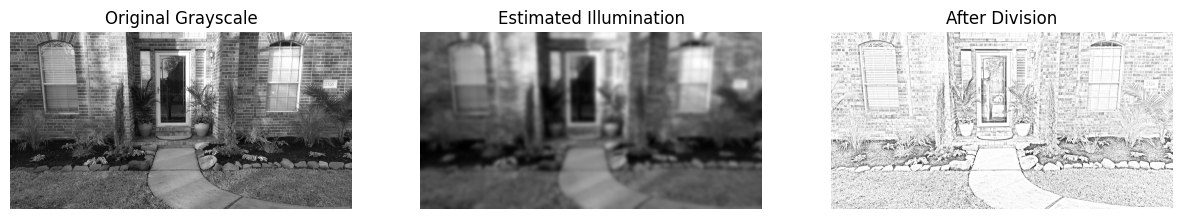

In [33]:
# Experiment: Use division to compensate for uneven lighting

# Create a smooth estimate of the background illumination
background = cv2.GaussianBlur(gray_image, (0, 0), sigmaX=25)

# Divide the original grayscale image by the illumination estimate
corrected_image = cv2.divide(gray_image, background, scale=255)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(background, cmap="gray")
plt.title("Estimated Illumination")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(corrected_image, cmap="gray")
plt.title("After Division")
plt.axis("off")

plt.show()

Dividing the grayscale image by a blurred estimate of its illumination reduced some of the effect of uneven lighting. This helped me understand how division can be used for normalization rather than simply making an image darker. The whole image gets dimmer and the differences between bright and dark areas are compressed.
A practical real-world use of image division is illumination correction. Imagine scanning a document where one side is brightly lit and the other side is shadowed. If you estimate the lighting pattern and divide the original image by that background illumination, you can normalize the brightness and make the text more uniform.


## **Brightness vs. Contrast**

**Brightness** and **contrast** are fundamental concepts in image processing, and they are often adjusted to improve the appearance of an image.

**Brightness** refers to the overall lightness or darkness of an image. Adjusting the brightness changes the intensity of all the pixels in the image uniformly.

**Contrast** refers to the difference in intensity between the darkest and brightest parts of an image. High contrast images have a wider range of intensity values (from dark to bright), whereas low contrast images appear more muted or washed out.

Let us have the visualization.

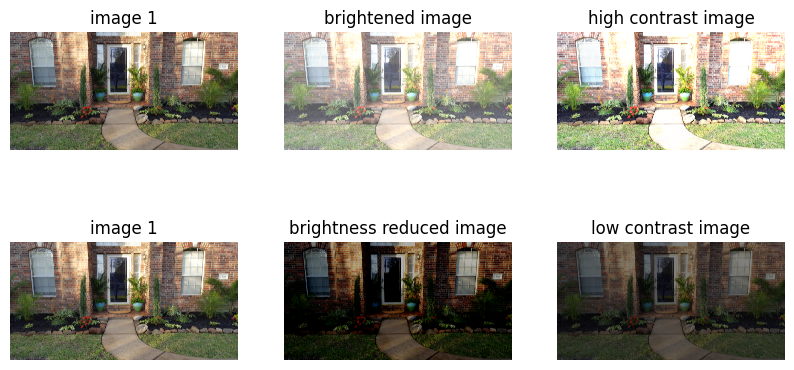

In [23]:
# Display the original and flipped images
plt.figure(figsize=(10, 5))

plt.subplot(2, 3, 1)
plt.imshow(image1)
plt.axis('off')
plt.title('image 1')

plt.subplot(2, 3, 2)
plt.imshow(brightened_image)
plt.axis('off')
plt.title('brightened image')

plt.subplot(2, 3, 3)
plt.imshow(high_contrast_image)
plt.axis('off')
plt.title('high contrast image')

plt.subplot(2, 3, 4)
plt.imshow(image1)
plt.axis('off')
plt.title('image 1')

plt.subplot(2, 3, 5)
plt.imshow(reduced_brightness)
plt.axis('off')
plt.title('brightness reduced image')

plt.subplot(2, 3, 6)
plt.imshow(low_contrast_image)
plt.axis('off')
plt.title('low contrast image')

plt.show()

**brightened** **image**: By adding a constant value to each pixel, the entire image becomes brighter.

**brightness reduced image**: By subtracting a constant value from each pixel, the image becomes darker.

**high contrast image**: By multiplying the pixel values by 2.0, the dark areas become darker, and the bright areas become brighter, increasing the contrast.

**low contrast image**: By multiplying the pixel values by 2.0, the difference between the bright and dark areas is reduced, making the image appear more muted and grayish.



---


Hence,

**Brightness** adjusts the overall lightness or darkness of an image by uniformly increasing or decreasing the pixel intensity.

**Contrast** adjusts the difference between the light and dark areas of an image, either enhancing or diminishing the separation between these extremes.

## **Rotateing an image**

**cv2.getRotationMatrix2D()** function computes the affine transformation matrix for rotating an image around a specified center by a given angle.
*   **center** tuple represents the coordinates of the center of rotation. The rotation will occur around this point,
*   **angle** parameter specifies the rotation angle in degrees. Positive values indicate counterclockwise rotation, while negative values indicate clockwise rotation and,
*   **1.0** parameter specifies the scaling factor for the image. A value of 1.0 means no scaling (i.e., the image will maintain its original size after rotation). If the value is greater than 1.0, the image will be scaled up, and if less than 1.0, it will be scaled down.


**cv2.warpAffine()** function applies an affine transformation to an image. This can include operations such as rotation, translation, and scaling.
*   **image** is the input image to which the affine transformation will be applied.
*   **rotation_matrix** is the 2x3 affine transformation matrix that specifies how the image should be transformed. It’s usually obtained from functions like cv2.getRotationMatrix2D(). In this case, it represents the rotation transformation.
*   **(new_w, new_h)** tuple specifies the size of the output image (width and height). It defines the dimensions of the output image where the transformed image will be placed.





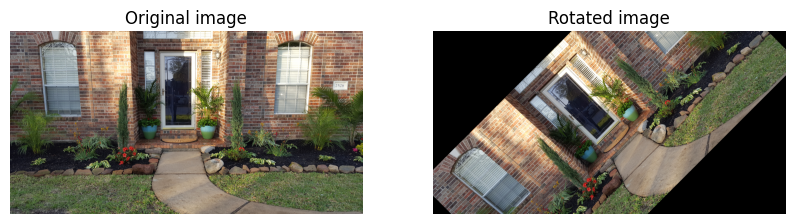

In [24]:
angle = 45  # You can change this to any angle you want

# Get the dimensions of the image
(h, w) = image.shape[:2]

# Define the center of the image
center = (w // 2, h // 2)

# Calculate the rotation matrix
rotation_matrix = cv2.getRotationMatrix2D(center, angle, 1.0)

# Perform the rotation with the new dimensions
rotated_image = cv2.warpAffine(image, rotation_matrix, (w, h))

# Convert BGR to RGB for displaying with matplotlib
rotated_image_rgb = cv2.cvtColor(rotated_image, cv2.COLOR_BGR2RGB)

# Display the original and flipped images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.axis('off')
plt.title('Original image')

plt.subplot(1, 2, 2)
plt.imshow(rotated_image_rgb)
plt.axis('off')
plt.title('Rotated image')

plt.show()

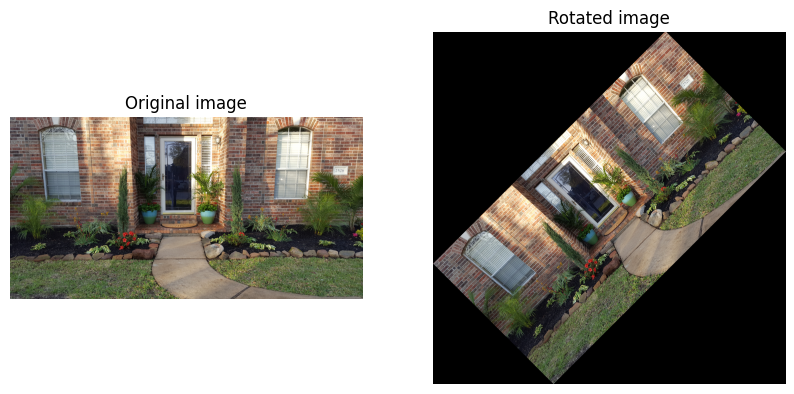

In [25]:
angle = 45  # You can change this to any angle you want

# Get the dimensions of the image
(h, w) = image.shape[:2]

# Define the center of the image
center = (w // 2, h // 2)

# Calculate the rotation matrix
rotation_matrix = cv2.getRotationMatrix2D(center, angle, 1.0)

# Calculate the cosine and sine of the rotation matrix
abs_cos = abs(rotation_matrix[0, 0])
abs_sin = abs(rotation_matrix[0, 1])

# Compute the new bounding dimensions of the image
new_w = int((h * abs_sin) + (w * abs_cos))
new_h = int((h * abs_cos) + (w * abs_sin))

# Adjust the rotation matrix to consider the translation
rotation_matrix[0, 2] += (new_w / 2) - center[0]
rotation_matrix[1, 2] += (new_h / 2) - center[1]

# Perform the rotation with the new dimensions
rotated_image = cv2.warpAffine(image, rotation_matrix, (new_w, new_h))

# Convert BGR to RGB for displaying with matplotlib
rotated_image_rgb = cv2.cvtColor(rotated_image, cv2.COLOR_BGR2RGB)

# Display the original and flipped images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.axis('off')
plt.title('Original image')

plt.subplot(1, 2, 2)
plt.imshow(rotated_image_rgb)
plt.axis('off')
plt.title('Rotated image')

plt.show()

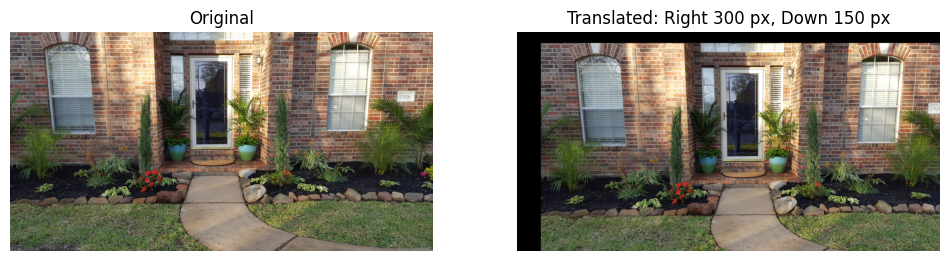

In [38]:
# Geometric transformation: translation

height, width = image.shape[:2]

# Shift image 300 pixels right and 150 pixels down
translation_matrix = np.float32([
    [1, 0, 300],
    [0, 1, 150]
])

translated_image = cv2.warpAffine(
    image,
    translation_matrix,
    (width, height)
)

translated_rgb = cv2.cvtColor(translated_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(translated_rgb)
plt.title("Translated: Right 300 px, Down 150 px")
plt.axis("off")

plt.show()

Part 3: ADVANCED PROCESSING TECHNIQUES

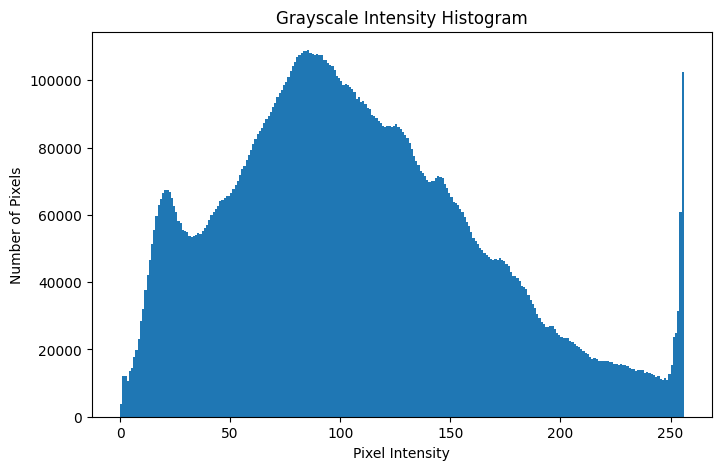

In [34]:
# Analyze grayscale histogram

plt.figure(figsize=(8, 5))

plt.hist(gray_image.ravel(), bins=256, range=[0, 256])

plt.title("Grayscale Intensity Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")

plt.show()

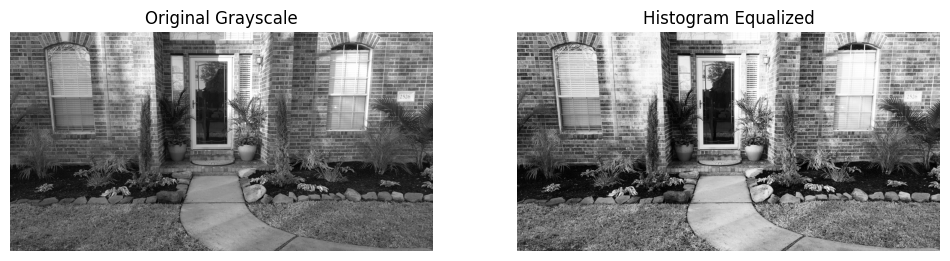

In [35]:
# Apply histogram equalization

equalized_image = cv2.equalizeHist(gray_image)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized_image, cmap="gray")
plt.title("Histogram Equalized")
plt.axis("off")

plt.show()

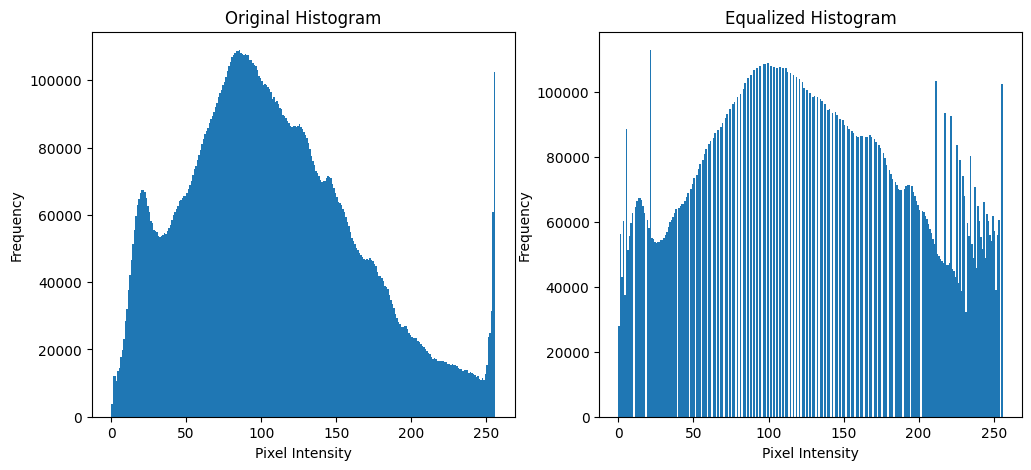

In [36]:
# Compare histograms before and after equalization

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(gray_image.ravel(), bins=256, range=[0, 256])
plt.title("Original Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(equalized_image.ravel(), bins=256, range=[0, 256])
plt.title("Equalized Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

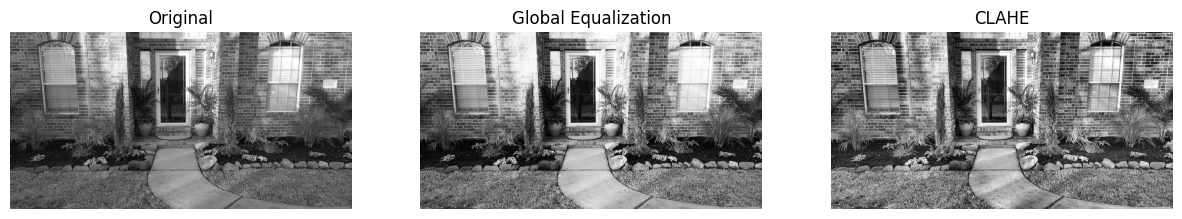

In [37]:
# Apply CLAHE - Contrast Limited Adaptive Histogram Equalization

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

clahe_image = clahe.apply(gray_image)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(equalized_image, cmap="gray")
plt.title("Global Equalization")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(clahe_image, cmap="gray")
plt.title("CLAHE")
plt.axis("off")

plt.show()

In [39]:
# Statistical comparison of enhancement methods

images_to_compare = {
    "Original": gray_image,
    "Global Equalization": equalized_image,
    "CLAHE": clahe_image
}

for name, img in images_to_compare.items():
    mean = np.mean(img)
    std_dev = np.std(img)

    print(f"{name}")
    print(f"  Mean intensity: {mean:.2f}")
    print(f"  Standard deviation: {std_dev:.2f}")
    print()

Original
  Mean intensity: 106.91
  Standard deviation: 57.56

Global Equalization
  Mean intensity: 128.09
  Standard deviation: 73.58

CLAHE
  Mean intensity: 122.54
  Standard deviation: 65.56



Part 4: CREATIVE EXPLORATION

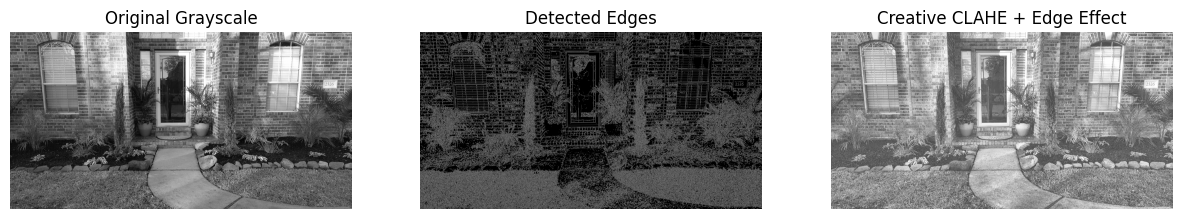

In [40]:
# Part 4: Creative Exploration
# Combine CLAHE enhancement with edge detection

# Enhance local contrast
enhanced = clahe.apply(gray_image)

# Detect edges
edges_creative = cv2.Canny(enhanced, 80, 150)

# Invert edges so lines are dark on a light background
inverted_edges = cv2.bitwise_not(edges_creative)

# Blend enhanced grayscale image with edge image
artistic_effect = cv2.addWeighted(
    enhanced, 0.7,
    inverted_edges, 0.3,
    0
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray_image, cmap='gray')
plt.title("Original Grayscale")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(edges_creative, cmap='gray')
plt.title("Detected Edges")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(artistic_effect, cmap='gray')
plt.title("Creative CLAHE + Edge Effect")
plt.axis('off')

plt.show()

Creative Processing Pipeline:
I first applied CLAHE to improve local contrast and bring out details in the brick, plants, and shaded areas. I then used Canny edge detection to identify structural boundaries. Finally, I blended the enhanced grayscale image with an inverted edge image to create a more stylized effect that emphasizes both texture and structure.

Part 5: AI CONNECTION
It seems traditional image processing operations such as resizing, grayscale conversion, blurring, edge detection, thresholding, contrast enhancement, and geometric transformations are still important in modern AI systems because they prepare and standardize image data before it is analyzed by a model. For example, resizing makes images consistent in size, blurring can reduce noise, and contrast enhancement can make features easier to distinguish. These operations do not “understand” the image, but they change the pixel data in ways that can make later AI processing more effective.

Modern image tools such as Nano Banana go far beyond these traditional techniques because they use learned models to understand image content and generate or modify images based on context. However, the traditional operations in this lab helped me see that AI image systems still depend on the same underlying digital image representation: pixels, intensity values, color channels, and transformations.
